In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "DSL-StrongPasswordData.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Output directory:", OUTPUT_DIR)

Project root: c:\HCI LAB\Keyboard_interaction
Dataset exists: True
Output directory: c:\HCI LAB\Keyboard_interaction\outputs


In [2]:
df = pd.read_csv(DATA_PATH)

participant = "s002"
session = 1
feature = "H.period"

selected = (
    df.loc[
        (df["subject"] == participant)
        & (df["sessionIndex"] == session),
        ["subject", "sessionIndex", "rep", feature],
    ]
    .sort_values("rep")
    .reset_index(drop=True)
)

signal = selected[feature].to_numpy(dtype=float)

print("Selected participant:", participant)
print("Selected session:", session)
print("Feature:", feature)
print("Number of observations:", len(signal))
print("Repetition range:", selected["rep"].min(), "to", selected["rep"].max())
print("Missing feature values:", selected[feature].isna().sum())
print("\nFirst 10 observations:")
display(selected.head(10))

Selected participant: s002
Selected session: 1
Feature: H.period
Number of observations: 50
Repetition range: 1 to 50
Missing feature values: 0

First 10 observations:


,subject,sessionIndex,rep,H.period
0,s002,1,1,0.1491
1,s002,1,2,0.1111
2,s002,1,3,0.1328
3,s002,1,4,0.1291
4,s002,1,5,0.1249
5,s002,1,6,0.1394
6,s002,1,7,0.1064
7,s002,1,8,0.0929
8,s002,1,9,0.0966
9,s002,1,10,0.1093


In [3]:
stats = pd.Series(signal, name=feature).agg(
    ["count", "mean", "std", "min", "max", "median"]
)

print("Time-domain statistics")
print(stats.to_string())

print(f"\nMean hold duration: {signal.mean():.4f} seconds")
print(f"Standard deviation: {signal.std(ddof=1):.4f} seconds")

Time-domain statistics
count     50.000000
mean       0.111288
std        0.015222
min        0.077600
max        0.149100
median     0.111800

Mean hold duration: 0.1113 seconds
Standard deviation: 0.0152 seconds


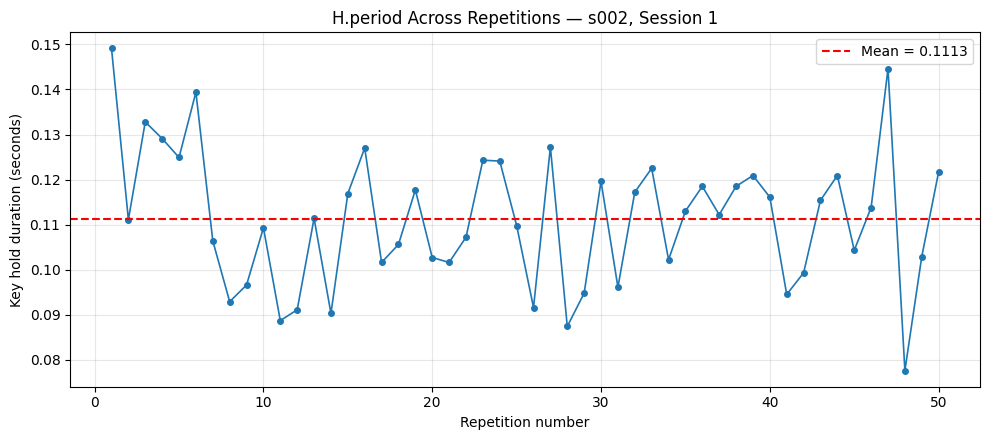

Saved figure: c:\HCI LAB\Keyboard_interaction\outputs\time_domain_H_period.png


In [4]:
plt.figure(figsize=(10, 4.5))

plt.plot(
    selected["rep"],
    signal,
    marker="o",
    markersize=4,
    linewidth=1.2,
)

plt.axhline(
    signal.mean(),
    color="red",
    linestyle="--",
    label=f"Mean = {signal.mean():.4f}",
)

plt.title(f"{feature} Across Repetitions — {participant}, Session {session}")
plt.xlabel("Repetition number")
plt.ylabel("Key hold duration (seconds)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = OUTPUT_DIR / "time_domain_H_period.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved figure:", figure_path)

FFT analysis
Number of observations: 50
Frequency resolution: 0.0200 cycles/repetition
Dominant nonzero frequency: 0.3600 cycles/repetition
Corresponding period: 2.78 repetitions
Peak amplitude: 0.008922


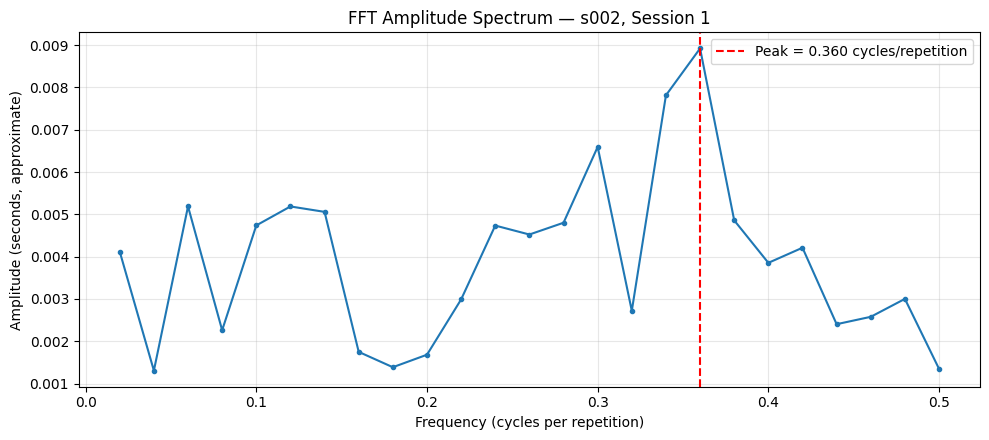

Saved figure: c:\HCI LAB\Keyboard_interaction\outputs\fft_H_period.png


In [5]:
from scipy.signal import detrend

# Remove the linear trend before analyzing oscillatory variation
detrended_signal = detrend(signal, type="linear")

# Apply a Hann window to reduce spectral leakage
window = np.hanning(len(detrended_signal))
windowed_signal = detrended_signal * window

# Calculate the one-sided FFT
N = len(windowed_signal)
fft_values = rfft(windowed_signal)
frequencies = rfftfreq(N, d=1.0)  # Units: cycles per repetition

# Approximate single-sided amplitude spectrum
amplitude = np.abs(fft_values) / window.sum()
amplitude[1:-1] *= 2

# Ignore the zero-frequency component when finding a peak
nonzero = frequencies > 0
peak_index = np.flatnonzero(nonzero)[np.argmax(amplitude[nonzero])]

dominant_frequency = frequencies[peak_index]
dominant_period = 1 / dominant_frequency

print("FFT analysis")
print("Number of observations:", N)
print(f"Frequency resolution: {1 / N:.4f} cycles/repetition")
print(f"Dominant nonzero frequency: {dominant_frequency:.4f} cycles/repetition")
print(f"Corresponding period: {dominant_period:.2f} repetitions")
print(f"Peak amplitude: {amplitude[peak_index]:.6f}")

# Plot the spectrum
plt.figure(figsize=(10, 4.5))
plt.plot(frequencies[nonzero], amplitude[nonzero], marker="o", markersize=3)
plt.axvline(
    dominant_frequency,
    color="red",
    linestyle="--",
    label=f"Peak = {dominant_frequency:.3f} cycles/repetition",
)

plt.title(f"FFT Amplitude Spectrum — {participant}, Session {session}")
plt.xlabel("Frequency (cycles per repetition)")
plt.ylabel("Amplitude (seconds, approximate)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

fft_figure_path = OUTPUT_DIR / "fft_H_period.png"
plt.savefig(fft_figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved figure:", fft_figure_path)

In [6]:
print("TIME-DOMAIN VS FREQUENCY-DOMAIN")
print("-" * 40)
print(f"Observations: {len(signal)}")
print(f"Mean: {np.mean(signal):.4f}")
print(f"Standard deviation: {np.std(signal, ddof=1):.4f}")
print(f"Minimum: {np.min(signal):.4f}")
print(f"Maximum: {np.max(signal):.4f}")
print(f"Dominant FFT component: {dominant_frequency:.4f} cycles/repetition")
print(f"Approximate period: {dominant_period:.2f} repetitions")

print("\nInterpretation:")
print(
    "Time-domain statistics describe the distribution and variation "
    "of key hold durations across trials."
)
print(
    "The FFT describes how variation is distributed across repetition-order "
    "frequencies; it does not measure continuous typing rhythm in hertz."
)

TIME-DOMAIN VS FREQUENCY-DOMAIN
----------------------------------------
Observations: 50
Mean: 0.1113
Standard deviation: 0.0152
Minimum: 0.0776
Maximum: 0.1491
Dominant FFT component: 0.3600 cycles/repetition
Approximate period: 2.78 repetitions

Interpretation:
Time-domain statistics describe the distribution and variation of key hold durations across trials.
The FFT describes how variation is distributed across repetition-order frequencies; it does not measure continuous typing rhythm in hertz.


In [7]:
print("Time-domain figure exists:", (OUTPUT_DIR / "time_domain_H_period.png").exists())
print("FFT figure exists:", (OUTPUT_DIR / "fft_H_period.png").exists())

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")

Time-domain figure exists: True
FFT figure exists: True

Output files:
fft_H_period.png - 90487 bytes
time_domain_H_period.png - 96444 bytes


In [8]:
print("PARTICIPANT:", participant)
print("SESSION:", session)
print("FEATURE:", feature)
print("OBSERVATIONS:", len(signal))

print("\nTIME-DOMAIN")
print(f"Mean: {np.mean(signal):.6f}")
print(f"Standard deviation: {np.std(signal, ddof=1):.6f}")
print(f"Minimum: {np.min(signal):.6f}")
print(f"Maximum: {np.max(signal):.6f}")
print(f"Median: {np.median(signal):.6f}")

print("\nFREQUENCY-DOMAIN")
print(f"Dominant frequency: {dominant_frequency:.6f} cycles/repetition")
print(f"Approximate period: {dominant_period:.4f} repetitions")
print(f"Peak amplitude: {amplitude[peak_index]:.6f}")

print("\nOUTPUT FILES")
for name in ["time_domain_H_period.png", "fft_H_period.png"]:
    path = OUTPUT_DIR / name
    print(f"{name}: exists={path.exists()}")

PARTICIPANT: s002
SESSION: 1
FEATURE: H.period
OBSERVATIONS: 50

TIME-DOMAIN
Mean: 0.111288
Standard deviation: 0.015222
Minimum: 0.077600
Maximum: 0.149100
Median: 0.111800

FREQUENCY-DOMAIN
Dominant frequency: 0.360000 cycles/repetition
Approximate period: 2.7778 repetitions
Peak amplitude: 0.008922

OUTPUT FILES
time_domain_H_period.png: exists=True
fft_H_period.png: exists=True
